# Churn: Logistic Regression vs Random Forest
חיזוי עזיבת לקוחות (`Exited`). חלוקה אקראית: 80% אימון, 20% בחינה.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

df = pd.read_csv('churn_modelling.csv')
print(df.shape)
print(df['Exited'].value_counts(normalize=True))
df.head()

(10000, 13)
Exited
0    0.7963
1    0.2037
Name: proportion, dtype: float64


,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## הכנת נתונים
מסירים עמודות מזהות (`CustomerId`, `Surname`) שאין בהן מידע לחיזוי. משתנים קטגוריים מקודדים ב-One-Hot, משתנים מספריים מנורמלים (חשוב לרגרסיה לוגיסטית).

In [2]:
X = df.drop(columns=['CustomerId', 'Surname', 'Exited'])
y = df['Exited']

cat_cols = ['Geography', 'Gender']
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print('train:', X_train.shape, ' test:', X_test.shape)

prep = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first'), cat_cols)])

train: (8000, 10)  test: (2000, 10)


## אימון המודלים

In [3]:
models = {
    'Logistic Regression': Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=1000))]),
    'Random Forest': Pipeline([('prep', prep), ('clf', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))]),
}
for name, m in models.items():
    m.fit(X_train, y_train)

## השוואה לפי מדדים

In [4]:
rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    rows.append({'Model': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred),
                 'Recall': recall_score(y_test, pred),
                 'F1': f1_score(y_test, pred),
                 'ROC-AUC': roc_auc_score(y_test, proba),
                 'Train Accuracy': m.score(X_train, y_train)})
results = pd.DataFrame(rows).set_index('Model').round(3)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,Train Accuracy
Model,,,,,,
Logistic Regression,0.808,0.589,0.187,0.284,0.775,0.811
Random Forest,0.864,0.770,0.469,0.583,0.854,1.000


## מטריצות בלבול

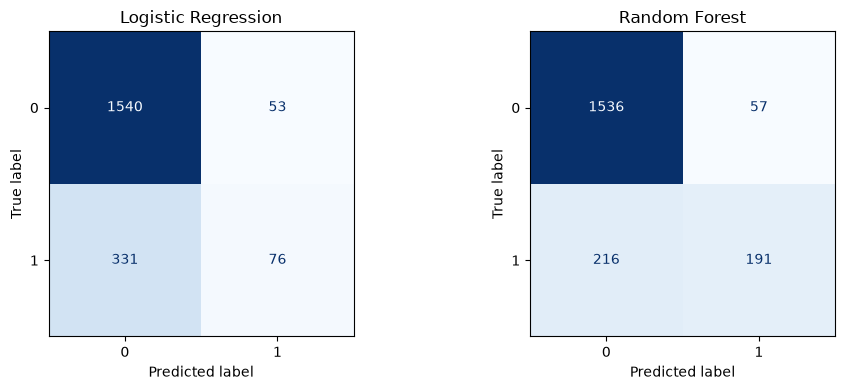

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## עקומות ROC

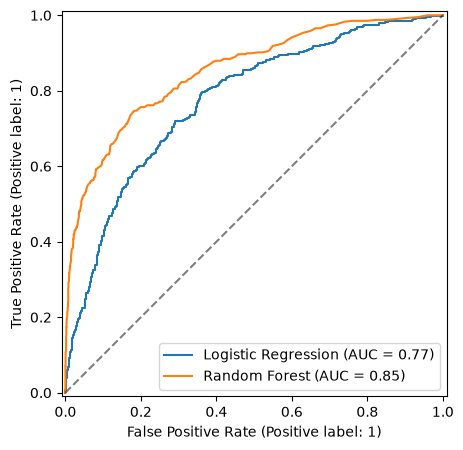

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, ax=ax, name=name)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.show()

## חשיבות משתנים (Random Forest)

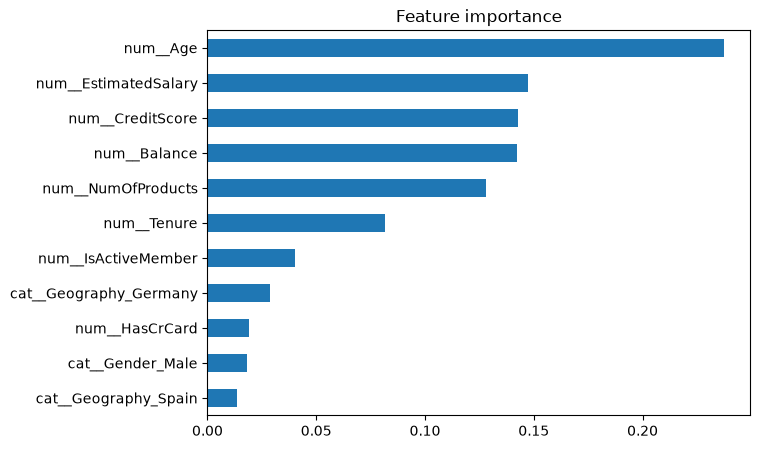

In [7]:
rf = models['Random Forest']
names = rf.named_steps['prep'].get_feature_names_out()
imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=names).sort_values()
imp.plot.barh(figsize=(7, 5), title='Feature importance'); plt.show()